# Text-to-Image Generation with a Pretrained Stable Diffusion Model

**Names:** Piyush Bhole 202401110063

In this notebook we use a pretrained Stable Diffusion model (`segmind/tiny-sd`, a distilled version of Stable Diffusion) from the Hugging Face **Diffusers** library to generate images from text prompts.
We then study how the following settings change the output:

1. **Number of inference steps** (`num_inference_steps`): how many times the model removes noise from the image
2. **Guidance scale** (`guidance_scale`): how strongly the image is pushed to follow the text prompt
3. **Prompt design and negative prompts**
4. **Sampling method (scheduler)**: PNDM, DDIM, Euler, Euler Ancestral and DPM-Solver++

> Use a GPU: *Runtime > Change runtime type > T4 GPU*

## 1. Install libraries

In [18]:
%%bash
pip install -q --upgrade diffusers accelerate transformers safetensors huggingface_hub datasets "pyarrow<24"

## 2. Load the pretrained model

In [2]:
import time
import torch
from diffusers import DiffusionPipeline
import matplotlib.pyplot as plt

model_id = "segmind/tiny-sd"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")
pipe.set_progress_bar_config(disable=True)   # hide the per-image progress bar

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


> **Note:** the message about the VAE `diffusion_pytorch_model.safetensors` is only a warning. The library falls back to another weight file and the model still loads correctly.

In [3]:
print(f"Is CUDA available?: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")

Is CUDA available?: True
Device name: Tesla T4


### 2.1 Components of the Stable Diffusion pipeline

A Stable Diffusion pipeline is made of four main parts that work together:

| Component | Class | Role |
|---|---|---|
| **Text encoder** | `CLIPTextModel` (+ tokenizer) | Converts the text prompt into numerical embeddings that the U-Net can use as a condition. |
| **U-Net** | `UNet2DConditionModel` | The denoising network. At every step it predicts the noise in the latent image, guided by the text embeddings. |
| **Scheduler** | e.g. `PNDMScheduler` | The sampling method. It decides the noise levels over the steps and how the predicted noise is removed at each step. |
| **VAE** | `AutoencoderKL` | Works in a compressed *latent space*. The decoder turns the final latent into a full-size RGB image (the encoder is used for image-to-image). |

**Pipeline flow:** prompt -> text encoder -> embeddings. Random noise (latent) -> U-Net + scheduler repeated for N steps (with classifier-free guidance) -> clean latent -> VAE decoder -> final image.
Working in latent space (8x smaller in each dimension) makes Stable Diffusion much faster than diffusing in pixel space.

In [4]:
print("Text encoder :", type(pipe.text_encoder).__name__)
print("Tokenizer    :", type(pipe.tokenizer).__name__)
print("U-Net        :", type(pipe.unet).__name__)
print("Scheduler    :", type(pipe.scheduler).__name__)
print("VAE          :", type(pipe.vae).__name__)

def n_params(m): return sum(p.numel() for p in m.parameters()) / 1e6
print(f"\nParameters (millions) -> text encoder: {n_params(pipe.text_encoder):.0f}, "
      f"U-Net: {n_params(pipe.unet):.0f}, VAE: {n_params(pipe.vae):.0f}")

# keep the default scheduler config so we can restore it after the scheduler experiment
default_scheduler_config = pipe.scheduler.config

Text encoder : CLIPTextModel
Tokenizer    : CLIPTokenizer
U-Net        : UNet2DConditionModel
Scheduler    : DPMSolverMultistepScheduler
VAE          : AutoencoderKL

Parameters (millions) -> text encoder: 123, U-Net: 323, VAE: 84


## 3. Generate an image from a text prompt

/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


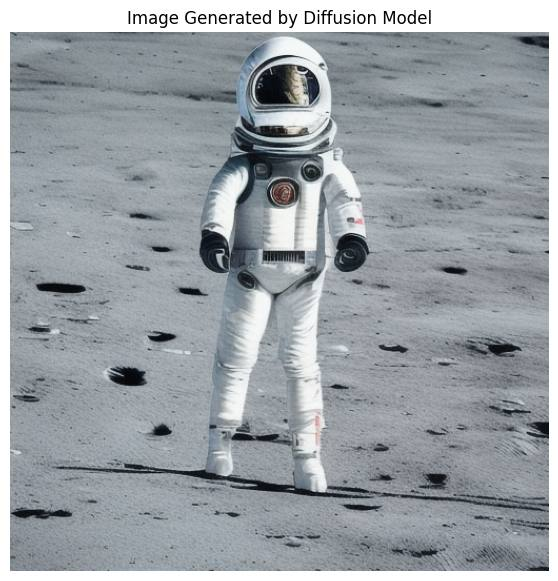

In [5]:
prompt = """
A cartoon astronaut standing on the moon
"""

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis('off')
plt.title("Image Generated by Diffusion Model")
plt.show()

**Observation:** the image shows a cartoon-style astronaut in a white suit standing on a grey, cratered moon surface with a large moon and stars in the background. It matches the prompt well. Small details such as the helmet visor and the suit panels are not perfectly realistic, and an extra moon-like ring/arc appears in the background that was not asked for.

## 4. Helper functions

To compare settings fairly we use the **same random seed** every time. Then the only thing that changes between images is the setting we are testing.

In [6]:
def generate(prompt, steps=25, guidance=7.5, seed=42, negative_prompt=None):
    generator = torch.Generator("cuda").manual_seed(seed)   # same seed = same starting noise
    start = time.time()
    img = pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator
    ).images[0]
    return img, time.time() - start


def show_images(images, titles, figsize=(20, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
    plt.show()

## 5. Experiment 1: Effect of the number of inference steps

The model starts from pure noise and removes a little noise at every step. We keep `guidance_scale = 7.5` fixed and change only the number of steps.

/usr/local/lib/python3.13/dist-packages/diffusers/configuration_utils.py:172: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)


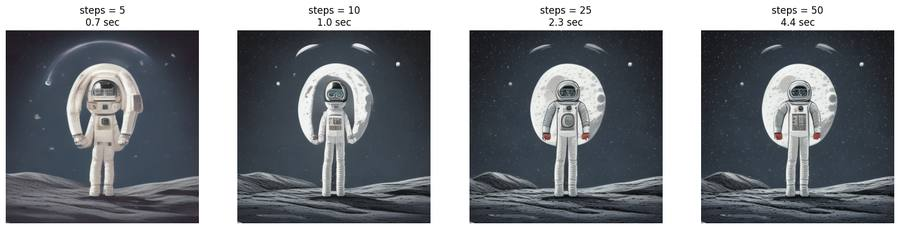

In [7]:
steps_list = [5, 10, 25, 50]
images, titles, times = [], [], []

for s in steps_list:
    img, t = generate(prompt, steps=s, guidance=7.5)
    images.append(img)
    times.append(t)
    titles.append(f"steps = {s}\n{t:.1f} sec")

show_images(images, titles)

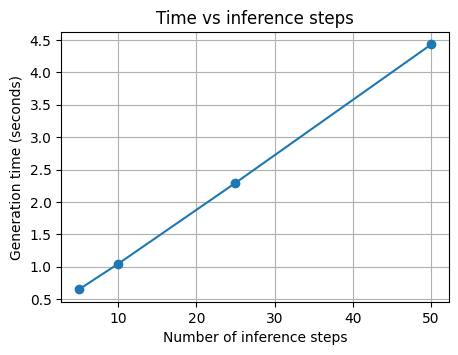

In [8]:
plt.figure(figsize=(5, 3.5))
plt.plot(steps_list, times, marker="o")
plt.xlabel("Number of inference steps")
plt.ylabel("Generation time (seconds)")
plt.title("Time vs inference steps")
plt.grid(True)
plt.show()

**Observations**

- **5 steps:** the image is rough. The astronaut's arms are merged into a strange ring shape, the surface is smooth and blurry, and details are missing, because the noise has not been removed enough.
- **10 steps:** the structure becomes correct (head, body, legs), but the suit details and the moon surface are still rough.
- **25 steps:** the image is clear and detailed, with a proper helmet, suit details and a textured moon surface.
- **50 steps:** almost identical to 25 steps, so the quality gain is very small, but generation takes about twice as long (about 4.8 s compared to 2.5 s).
- Generation time increases almost linearly with the number of steps (see the graph). This is a trade-off between quality and speed, and about 20 to 30 steps is a good choice for this model.

## 6. Experiment 2: Effect of the guidance scale

The guidance scale controls how closely the image follows the text prompt (classifier-free guidance). We keep `steps = 25` fixed and change only the guidance scale.

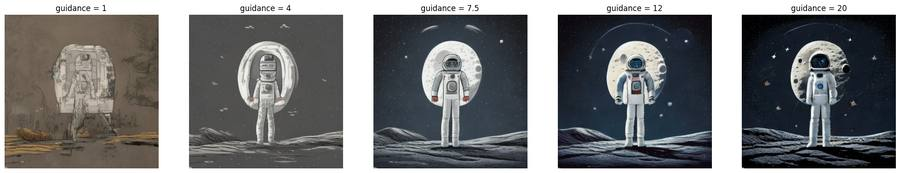

In [9]:
guidance_list = [1, 4, 7.5, 12, 20]
images, titles = [], []

for g in guidance_list:
    img, t = generate(prompt, steps=25, guidance=g)
    images.append(img)
    titles.append(f"guidance = {g}")

show_images(images, titles, figsize=(25, 5))

**Observations**

- **Guidance = 1:** the model almost ignores the prompt. The result is a brownish, messy picture where no clear astronaut or moon can be recognised.
- **Guidance = 4:** an astronaut is visible, but the image is grey, flat and has odd shapes around the figure.
- **Guidance = 7.5:** a good balance. The prompt is followed, the colours look natural and the details are clear.
- **Guidance = 12:** the astronaut and moon are very clear, with stronger contrast and darker colours.
- **Guidance = 20:** very high contrast and dark, saturated colours, with a less natural, over-processed look and unwanted extra objects floating in the sky.
- So a higher guidance scale does not always give a better image. Values of about 7 to 12 work best here.

## 7. Experiment 3: Effect of changing the prompt

We keep steps and guidance fixed (25 and 7.5) and only change the text.

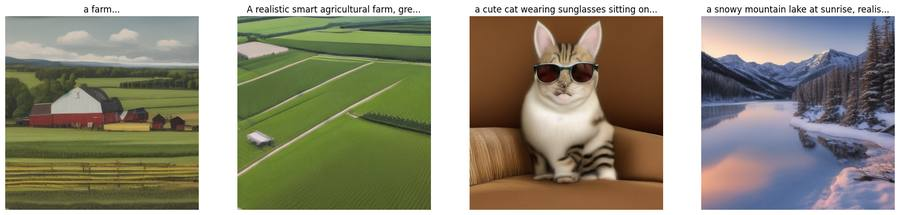

In [10]:
prompts = [
    "a farm",
    "A realistic smart agricultural farm, green crops, automated irrigation systems, drones monitoring the fields, clear blue sky, high quality",
    "a cute cat wearing sunglasses sitting on a sofa, digital art",
    "a snowy mountain lake at sunrise, realistic photo",
]

images, titles = [], []
for p in prompts:
    img, t = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(p[:40] + "...")

show_images(images, titles, figsize=(22, 5))

**Observations**

- A short prompt (`a farm`) gives a generic image (red barn, fences, fields). The model fills in the missing details by itself.
- A detailed prompt gives a result closer to what we describe: a green aerial view of crop fields with a clear blue sky. Small objects such as drones are still missing, which shows the limits of this small model.
- Style words like `realistic photo` or `digital art` clearly change the look of the image (photo-like lake scene vs. digital-art cat).
- More descriptive prompts give more control over the output.

## 8. Experiment 4: Prompt engineering and negative prompts

A good prompt usually has the structure: **subject + details + style + lighting + quality words**.
A **negative prompt** tells the model what to avoid. It is used in classifier-free guidance as the "unconditional" direction, so the model is pushed away from those concepts.
(Note: negative prompts have no effect when `guidance_scale = 1`, because guidance is turned off.)

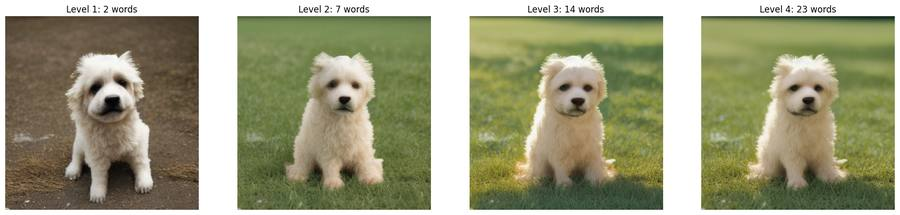

Level 1: a dog
Level 2: a golden retriever puppy sitting on grass
Level 3: a golden retriever puppy sitting on green grass, sunny day, soft lighting, realistic photo
Level 4: a golden retriever puppy sitting on green grass, sunny day, soft natural lighting, shallow depth of field, professional photography, highly detailed, sharp focus


In [11]:
# 8.1 Progressively better prompts (same subject, same seed)
prompt_levels = [
    "a dog",
    "a golden retriever puppy sitting on grass",
    "a golden retriever puppy sitting on green grass, sunny day, soft lighting, realistic photo",
    "a golden retriever puppy sitting on green grass, sunny day, soft natural lighting, "
    "shallow depth of field, professional photography, highly detailed, sharp focus",
]
images, titles = [], []
for i, p in enumerate(prompt_levels):
    img, _ = generate(p, steps=25, guidance=7.5)
    images.append(img)
    titles.append(f"Level {i+1}: {len(p.split())} words")
show_images(images, titles, figsize=(22, 5))
for i, p in enumerate(prompt_levels):
    print(f"Level {i+1}: {p}")

**Observations (prompt structure)**

Compare the four images above. Adding the subject details, then the style / lighting words and finally quality words should make the image more specific, better lit and sharper. Very short prompts leave many choices to the model, so the result is less controlled.

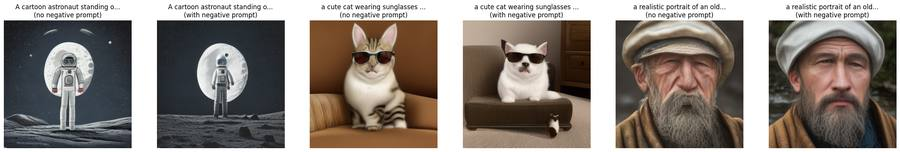

Negative prompt used: blurry, low quality, distorted, deformed, extra limbs, bad anatomy, watermark, text


In [12]:
# 8.2 Effect of a negative prompt (same prompt, same seed, same settings)
neg = "blurry, low quality, distorted, deformed, extra limbs, bad anatomy, watermark, text"

test_prompts = [
    "A cartoon astronaut standing on the moon",
    "a cute cat wearing sunglasses sitting on a sofa, digital art",
    "a realistic portrait of an old fisherman, detailed face",
]

images, titles = [], []
for p in test_prompts:
    img_a, _ = generate(p, steps=25, guidance=7.5)
    img_b, _ = generate(p, steps=25, guidance=7.5, negative_prompt=neg)
    images += [img_a, img_b]
    titles += [p[:30] + "...\n(no negative prompt)", p[:30] + "...\n(with negative prompt)"]

show_images(images, titles, figsize=(30, 5.5))
print("Negative prompt used:", neg)

**Observations (negative prompts)**

Compare each pair of images (without / with the negative prompt, same seed). The negative prompt should reduce blur, distortion and strange shapes (for example, the faces and bodies look cleaner), while the main subject stays the same because the seed is fixed. The change is usually small but useful, and it helps most for people and animals where anatomy errors are common.

## 9. Experiment 5: Effect of the sampling method (scheduler)

The **scheduler** (sampler) decides how the noise is removed at every step. All schedulers use the same U-Net, but they differ in the maths used for each step, so they differ in **speed, quality at low step counts, and randomness**.

| Scheduler | Short description |
|---|---|
| **PNDM** | Pseudo numerical method, the default for Stable Diffusion v1. Good quality, deterministic. |
| **DDIM** | Deterministic version of DDPM. Allows few steps, gives consistent results for the same seed. |
| **Euler** | Simple and fast ODE solver, deterministic. |
| **Euler Ancestral (Euler-A)** | Adds fresh noise at each step, so it never fully "converges"; the image keeps changing with the step count. More creative, less predictable. |
| **DPM-Solver++ (DPM++)** | High-order solver that gives good quality in only 15 to 25 steps. |

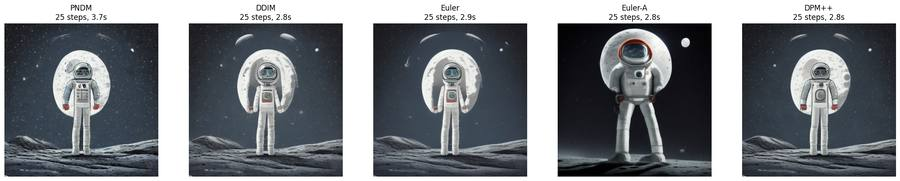

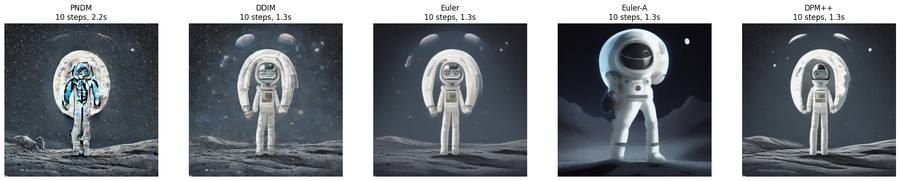

In [13]:
from diffusers import (PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler,
                       EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)

schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler-A": EulerAncestralDiscreteScheduler,
    "DPM++": DPMSolverMultistepScheduler,
}

def run_schedulers(steps, prompt=prompt):
    imgs, titles, times = [], [], []
    for name, cls in schedulers.items():
        pipe.scheduler = cls.from_config(default_scheduler_config)
        img, t = generate(prompt, steps=steps, guidance=7.5)
        imgs.append(img); times.append(t)
        titles.append(f"{name}\n{steps} steps, {t:.1f}s")
    return imgs, titles, times

# 9.1 Same number of steps (25)
imgs_25, titles_25, times_25 = run_schedulers(25)
show_images(imgs_25, titles_25, figsize=(26, 5.5))

# 9.2 Few steps (10): which sampler gives a good image fastest?
imgs_10, titles_10, times_10 = run_schedulers(10)
show_images(imgs_10, titles_10, figsize=(26, 5.5))

# restore the default scheduler for the remaining experiments
pipe.scheduler = PNDMScheduler.from_config(default_scheduler_config)

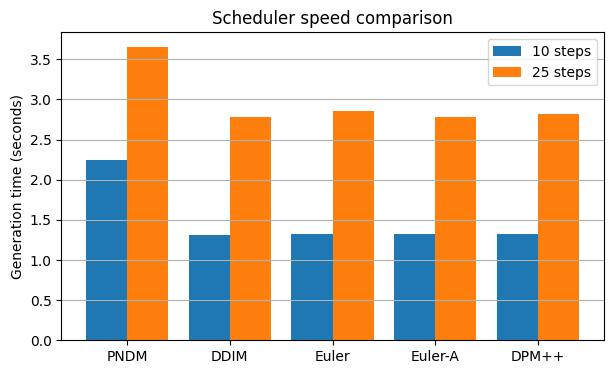

In [14]:
# Speed comparison of schedulers
names = list(schedulers.keys())
x = range(len(names))
plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], times_10, width=0.4, label="10 steps")
plt.bar([i + 0.2 for i in x], times_25, width=0.4, label="25 steps")
plt.xticks(list(x), names)
plt.ylabel("Generation time (seconds)")
plt.title("Scheduler speed comparison")
plt.legend(); plt.grid(axis="y")
plt.show()

**Observations (schedulers)**

*Compare the two rows of images above while reading these points. Confirm them with your own output.*

- With the **same number of steps**, all schedulers produce a similar astronaut scene, but the details (suit, moon texture, contrast) differ slightly because each sampler follows a different path from noise to image.
- At **10 steps**, the faster-converging solvers (**DPM++**, **DDIM**, **Euler**) usually give a cleaner image than the default **PNDM**, which needs more steps to settle.
- **Euler-A** is stochastic (adds noise at each step), so its image looks different from the others and changes when the step count changes.
- **Time per step is almost the same** for all schedulers, since the U-Net dominates the cost. A better sampler is therefore faster only because it needs fewer steps for the same quality.
- Practical choice: **DPM++** or **Euler** with about 20 steps for speed, **DDIM** when reproducible results are needed, **Euler-A** for creative variety.

## 10. Combined effect: steps and guidance together

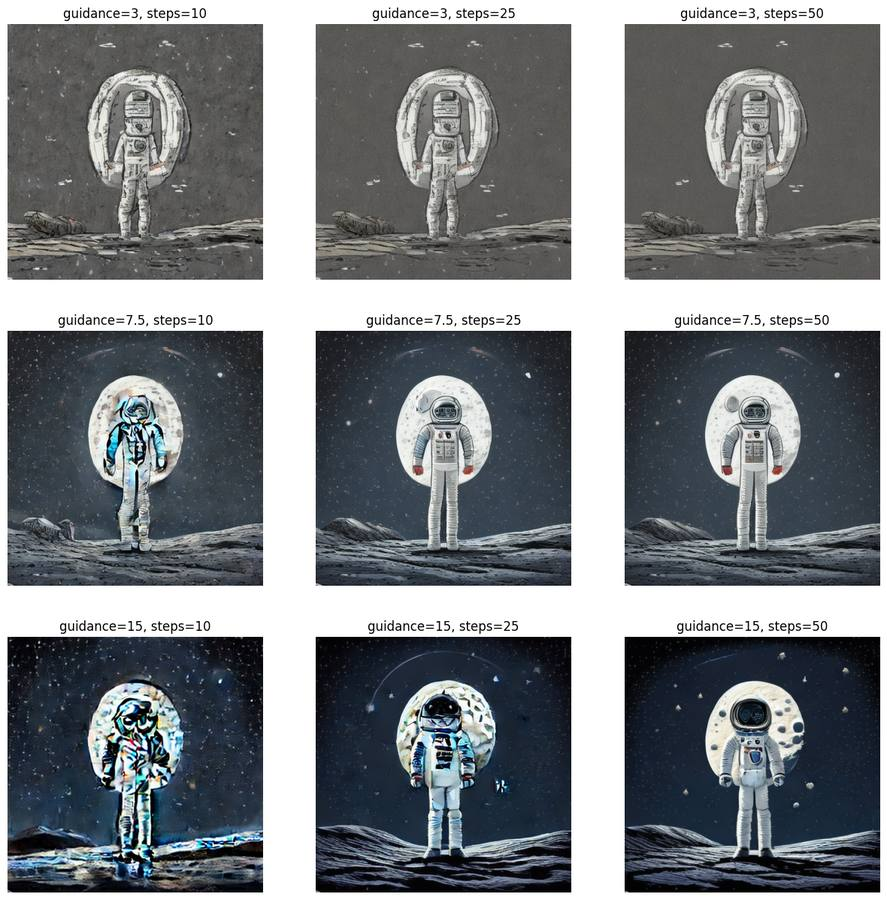

In [15]:
steps_values = [10, 25, 50]
guidance_values = [3, 7.5, 15]

plt.figure(figsize=(15, 15))
k = 1
for g in guidance_values:
    for s in steps_values:
        img, _ = generate(prompt, steps=s, guidance=g)
        plt.subplot(3, 3, k)
        plt.imshow(img)
        plt.title(f"guidance={g}, steps={s}")
        plt.axis('off')
        k += 1
plt.show()

**Observations**

- At low guidance (3) the image stays flat, grey and ring-shaped for every step count, and it barely changes from 10 to 50 steps. More steps cannot fix weak prompt-following.
- At guidance 7.5, 10 steps still shows an incomplete suit and a ring around the figure; the image becomes clean and detailed at 25 steps, and 50 steps adds almost nothing.
- At high guidance (15) the colours and contrast become much stronger and darker, extra objects float in the sky, and 10 steps gives a distorted figure. More steps (25, 50) clean the figure but keep the harsh, dark look.
- The best results appear in the middle: guidance about 7.5 with 25 steps.
- The two settings work together. Steps control *how well the noise is cleaned*, guidance controls *how strongly the prompt is followed*.


## 11. Quantitative check: CLIP score

So far the comparison was visual. We can also measure **prompt-image similarity** with a CLIP model (higher score = the image matches the text better). This is only a rough indicator, but it supports the visual observations.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

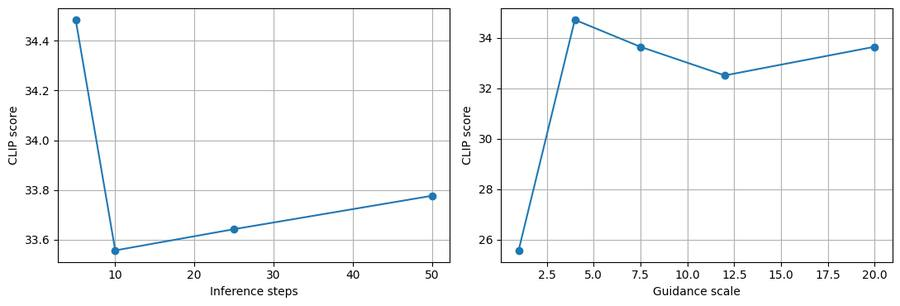

Steps   : {5: 34.5, 10: 33.6, 25: 33.6, 50: 33.8}
Guidance: {1: 25.6, 4: 34.7, 7.5: 33.6, 12: 32.5, 20: 33.6}


In [16]:
from transformers import CLIPProcessor, CLIPModel

clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def clip_score(img, text):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to("cuda")
    out = clip_model(**inputs)
    return out.logits_per_image.item()          # cosine similarity * 100

# CLIP score vs guidance scale
g_values = [1, 4, 7.5, 12, 20]
g_scores = [clip_score(generate(prompt, steps=25, guidance=g)[0], prompt.strip()) for g in g_values]

# CLIP score vs inference steps
s_values = [5, 10, 25, 50]
s_scores = [clip_score(generate(prompt, steps=s, guidance=7.5)[0], prompt.strip()) for s in s_values]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(s_values, s_scores, marker="o"); ax[0].set_xlabel("Inference steps"); ax[0].set_ylabel("CLIP score"); ax[0].grid(True)
ax[1].plot(g_values, g_scores, marker="o"); ax[1].set_xlabel("Guidance scale"); ax[1].set_ylabel("CLIP score"); ax[1].grid(True)
plt.tight_layout(); plt.show()

print("Steps   :", dict(zip(s_values, [round(v, 1) for v in s_scores])))
print("Guidance:", dict(zip(g_values, [round(v, 1) for v in g_scores])))

**Observations (CLIP score)**

The CLIP score is expected to rise quickly from very low steps / very low guidance and then flatten out, which agrees with the visual results. The score does not measure image beauty or realism, only text-image match, so it should be used together with visual inspection.

## 12. Conclusion

| Setting | Too low | Good range | Too high |
|---|---|---|---|
| Inference steps | Rough, distorted shapes, missing details | about 20 to 30 | Very little extra quality, much slower |
| Guidance scale | Ignores the prompt, messy image | about 7 to 12 | Over-saturated, harsh contrast, unwanted objects |
| Prompt detail | Generic image, random choices by the model | Subject + style + lighting + quality words | Too many words may be ignored by a small model |
| Negative prompt | - | Short list of unwanted qualities | Not useful if guidance is 1 |
| Scheduler | PNDM needs more steps | DPM++ / Euler / DDIM at 15 to 25 steps | Euler-A changes with steps (stochastic) |

- The Stable Diffusion pipeline has four main parts: the **text encoder** (prompt to embeddings), the **U-Net** (noise prediction), the **scheduler** (sampling method) and the **VAE** (latent to image).
- **Inference steps** control how much the noise is cleaned. More steps help only up to a point, then they just cost time (time grows linearly with steps).
- **Guidance scale** controls how strictly the image follows the prompt. The best images come from a medium value.
- **Prompt design** and **negative prompts** give extra control over content and style.
- **Schedulers** change the quality reached for a given number of steps. Better solvers (DPM++, Euler, DDIM) allow fewer steps, which saves time.
- Best settings for this model: around **25 steps** (about 20 with DPM++), guidance of about **7.5**, a detailed prompt and a short negative prompt.